### Centroid based clustering

centroids are choosen randomnly initially. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
data = pd.read_csv("Mall_Customers.csv")

In [3]:
data.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [4]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
data.shape

(200, 5)

In [7]:
print(data["Age"].max())

70


In [8]:
print(data.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [9]:
print(data.duplicated().sum())

0


In [10]:
x = data[["Annual Income (k$)", "Spending Score (1-100)"]]

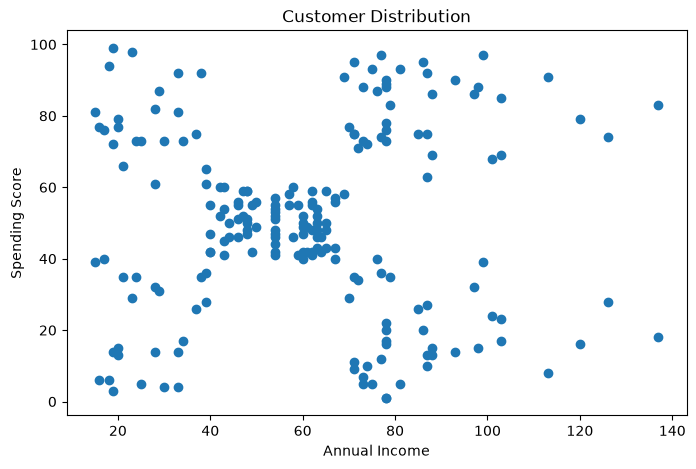

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x['Annual Income (k$)'],
    x['Spending Score (1-100)']
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Distribution")

plt.show()

scaling is imp in k means clustering because it uses distance calculation

In [12]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

#### Elbow method

look for the points where the distance between the datapoints to their centroids becomes less with respect to other datapints in the same cluster

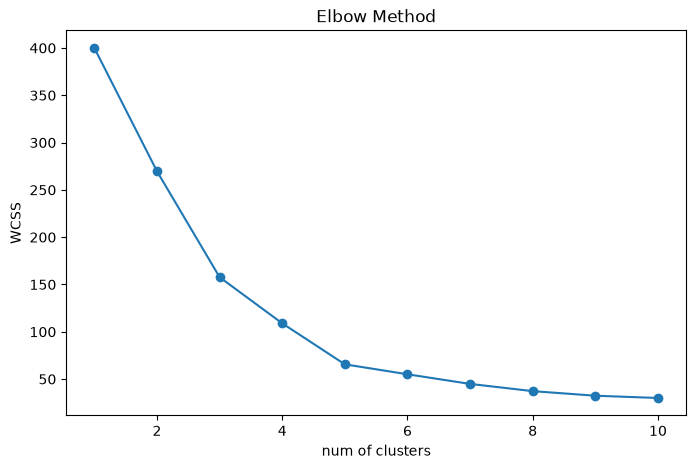

[400.00000000000006, 269.691012192764, 157.7040081503594, 108.92131661364358, 65.56840815571681, 55.057348270386015, 44.86475569922557, 37.228187677585886, 32.39226763033117, 29.981897788243703]


In [13]:
# does all this to find the best num of clusters

wcss = [] #store values calculated for different numbers of clusters.
for i in range(1,11):
    kmeans = KMeans(n_clusters = i, init = "k-means++", random_state = 42, n_init =10)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_) #inertia_ = WCSS ->it teels how compact the clusters are

# elbow point — the bend where the rate of decrease sharply slows down. Adding more clusters past this point gives very little extra benefit.

plt.figure(figsize = (8,5))
plt.plot(range(1,11), wcss, marker = 'o')  #WCSS obtained from one trained model / one iteration
plt.xlabel("num of clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

print(wcss)

# low inertia value means high compactness in the cluster
# choose num of clusters based on significant reduction in wcss

In [14]:
kmeans = KMeans(n_clusters = 5, init = "k-means++", random_state = 42, n_init =10)

kmeans.fit(x_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-0.

In [18]:
data.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [17]:
labels = kmeans.labels_  # numerical label of each datapoint
data['Cluster'] = labels  # creates a new column with label for each row

cluster_names = {
    0: 'Average Customers',
    1: 'Premium Customers',
    2: 'High-Spending Customers',
    3: 'Potential Customers',
    4: 'Low-Value Customers'
}

data['Cluster_Name'] = data['Cluster'].map(cluster_names)
print(data.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster             Cluster_Name  
0        4      Low-Value Customers  
1        2  High-Spending Customers  
2        4      Low-Value Customers  
3        2  High-Spending Customers  
4        4      Low-Value Customers  


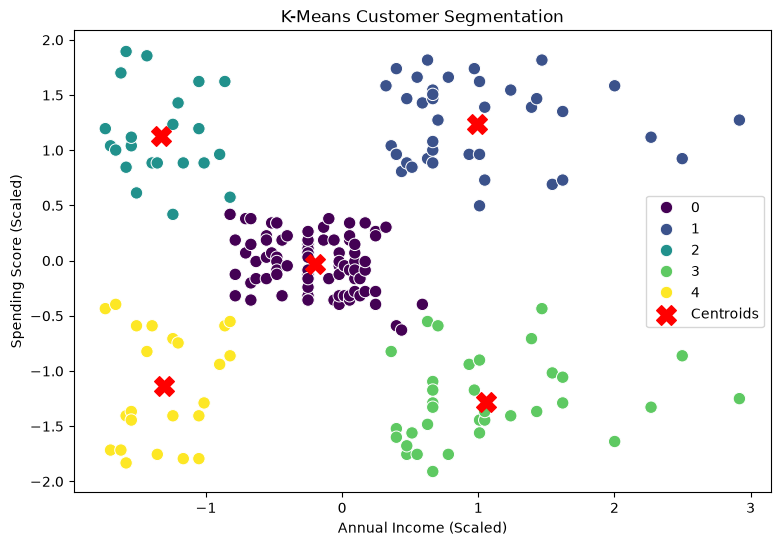

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=x_scaled[:, 0], # Takes the first feature
    y=x_scaled[:, 1],
    hue=labels,
    palette='viridis',
    s=80 # size of points
)

centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0], # x coordinate of each centroid
    centroids[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.title("K-Means Customer Segmentation")

plt.legend()
plt.show()

# positive shows above average values and vice versa

In [35]:
new_data = [[15,39]]
scaled = scaler.transform(new_data)
results = kmeans.predict(scaled)
print(results)

TypeError: memoryview: invalid slice key